<center><h1>Bhatt_Om_HW4</h1></center>
<br>
<br>

Name: Om Bhatt
<br>
Github Username: OmBhatt18
<br>
USC ID: 7536194801

| Section | Content |
|---|---|
| 1 | Feature creation/extraction (Homework 3 code, re-used here because Part 2 needs it) |
| 2(a) | Binary classification (bending vs. other) with logistic regression + recursive feature elimination |
| 2(b) | Binary classification with L1-penalized logistic regression |
| 2(c) | Multi-class classification: L1-penalized multinomial regression, Gaussian and Multinomial Naïve Bayes |
| 3 | ISLR 4.8.3 |
| 4 | ISLR 4.8.7 |

The notebook reads the AReM data from `../data/AReM/` (one folder per activity) and saves its CSV outputs to `../output/`, both relative to the `notebooks/` folder.

In [1]:
import os, re, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, auc)
from sklearn.exceptions import ConvergenceWarning

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

DATA_DIR = os.path.join('..', 'data', 'AReM')
OUT_DIR = os.path.join('..', 'output')
os.makedirs(OUT_DIR, exist_ok=True)
ACTIVITIES = ['bending1','bending2','cycling','lying','sitting','standing','walking']
SERIES = ['avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']
SEED = 42
L_VALUES = range(1, 21)

missing = [a for a in ACTIVITIES if not os.path.isdir(os.path.join(DATA_DIR, a))]
if missing: print("can't find:", missing)

---
## 1. Time Series Classification Part 1: Feature Creation/Extraction

*(Not graded with this homework. This is the Homework 3 code, kept here because Part 2 builds on it.)*

### 1(a) Load the data
Each file has a few `#` header lines, then `time` and the 6 series. A few files need minor cleaning: `bending2/dataset4.csv` uses spaces instead of commas, `cycling/dataset9.csv` and `cycling/dataset14.csv` have a trailing comma, and `sitting/dataset8.csv` has 479 rows instead of 480. The loader splits on commas and whitespace together, so no file has to be edited by hand.

In [2]:
def load(path):
    rows = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            # bending2/dataset4 is space separated, cycling 9 and 14 have a trailing comma
            vals = [v for v in re.split(r'[,\s]+', line) if v]
            if len(vals) >= 7:
                rows.append([float(v) for v in vals[:7]])
    return pd.DataFrame(rows, columns=['time'] + SERIES)

def num(fn):
    return int(re.search(r'dataset(\d+)\.csv$', fn).group(1))

instances = []
for act in ACTIVITIES:
    for fn in sorted(glob.glob(os.path.join(DATA_DIR, act, 'dataset*.csv')), key=num):
        instances.append({'activity': act, 'file': num(fn), 'data': load(fn)})

assert len(instances) == 88
print(len(instances), 'instances')

88 instances


### 1(b) Train / test split
* **Test:** datasets 1 and 2 in `bending1` and `bending2`, and datasets 1, 2, 3 in every other folder (19 instances).
* **Train:** everything else (69 instances).

In [3]:
for d in instances:
    cutoff = 2 if d['activity'].startswith('bending') else 3
    d['split'] = 'test' if d['file'] <= cutoff else 'train'

pd.crosstab([d['activity'] for d in instances], [d['split'] for d in instances],
            rownames=['activity'], colnames=['split'], margins=True)

split,test,train,All
activity,,,
bending1,2,5,7
bending2,2,4,6
cycling,3,12,15
lying,3,12,15
sitting,3,12,15
standing,3,12,15
walking,3,12,15
All,19,69,88


### 1(c) Feature extraction

In Homework 3 I extracted 7 time-domain statistics (min, max, mean, median, std, 1st quartile, 3rd quartile) from each of the 6 series, and in 1(c)iv selected **mean, standard deviation and max** as the three most important features (mean has the highest ANOVA F-statistic; std and max add information that is not just a repeat of the mean).

Part 2 needs the same features computed after breaking every series into `l` pieces, so `extract_features()` below takes `l` as an argument. Each series is split into `l` consecutive, approximately equal pieces with `np.array_split`, and the statistics are computed on every piece. Feature names are `<stat><series>` when `l = 1` (e.g. `mean1`) and `<stat><series>_<piece>` when `l > 1` (e.g. `mean1_2` is the mean of the 2nd half of series 1).

Breaking the series **does not change the number of instances** (still 69 train / 19 test), only the number of features: `3 stats × 6 series × l` = `18·l` features.

In [4]:
STATS = ['min', 'max', 'mean', 'median', 'std', '1st_quart', '3rd_quart']
SEL = ['mean', 'std', 'max']   # picked in HW3 1(c)iv

FUNCS = {
    'min': np.min, 'max': np.max, 'mean': np.mean, 'median': np.median,
    'std': lambda x: np.std(x, ddof=1),
    '1st_quart': lambda x: np.quantile(x, .25),
    '3rd_quart': lambda x: np.quantile(x, .75),
}

def extract_features(df, l=1, stats=SEL):
    out = {}
    for k, col in enumerate(SERIES, 1):
        # array_split is fine with uneven splits (480 / 7 etc), last chunks just get 1 less row
        for j, piece in enumerate(np.array_split(df[col].values, l), 1):
            tag = str(k) if l == 1 else f'{k}_{j}'
            for s in stats:
                out[s + tag] = FUNCS[s](piece)
    return out

In [5]:
META = ['activity', 'file', 'split']

def build_features(l, stats=SEL):
    rows = []
    for d in instances:
        row = {m: d[m] for m in META}
        row.update(extract_features(d['data'], l, stats))
        rows.append(row)
    return pd.DataFrame(rows)

FEATS = {l: build_features(l) for l in L_VALUES}

print('n features:', {l: FEATS[l].shape[1] - 3 for l in (1, 2, 5, 20)})
FEATS[1].head()

n features: {1: 18, 2: 36, 5: 90, 20: 360}


,activity,file,split,mean1,std1,max1,mean2,std2,max2,mean3,std3,max3,mean4,std4,max4,mean5,std5,max5,mean6,std6,max6
0,bending1,1,test,40.624792,1.476967,45.00,0.358604,0.322605,1.30,19.040937,4.462952,29.50,0.832542,0.965659,7.23,34.311292,2.188449,38.25,0.570583,0.582915,1.92
1,bending1,2,test,42.812812,1.435550,45.67,0.372437,0.289158,1.22,20.096979,3.893737,29.50,0.876438,1.047259,5.76,33.024583,1.995255,38.50,0.571083,0.601010,3.11
2,bending1,3,train,43.954500,1.558835,47.40,0.426250,0.338690,1.70,22.122354,3.030943,29.75,0.497312,0.550657,4.44,35.588458,1.999604,38.50,0.493292,0.513506,1.79
3,bending1,4,train,42.179812,3.670666,47.75,0.696042,0.630860,3.00,22.183625,3.810469,30.00,0.989917,0.953730,5.15,33.493917,3.849448,38.67,0.613521,0.524317,2.18
4,bending1,5,train,41.678063,2.243490,45.75,0.535979,0.405469,2.83,19.006563,4.087107,28.25,0.841875,0.928801,6.42,29.857083,2.411026,37.50,0.383292,0.389164,1.79


In [6]:
def split_xy(F, target='binary'):
    cols = [c for c in F.columns if c not in META]
    tr, te = F[F.split == 'train'], F[F.split == 'test']
    if target == 'binary':
        y = lambda d: d.activity.str.startswith('bending').astype(int).values
    else:
        y = lambda d: d.activity.values
    return tr[cols], y(tr), te[cols], y(te)

_, ytr, _, yte = split_xy(FEATS[1])
print(f'train: {ytr.sum()} bending / {(ytr == 0).sum()} other')
print(f'test:  {yte.sum()} bending / {(yte == 0).sum()} other')

train: 9 bending / 60 other
test:  4 bending / 15 other


---
## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### 2(a) Binary Classification Using Logistic Regression

The positive class is **bending** (`bending1` + `bending2`), the negative class is every other activity.

#### 2(a)i Scatter plots of mean, std, max of time series 1, 2 and 6 (training set)

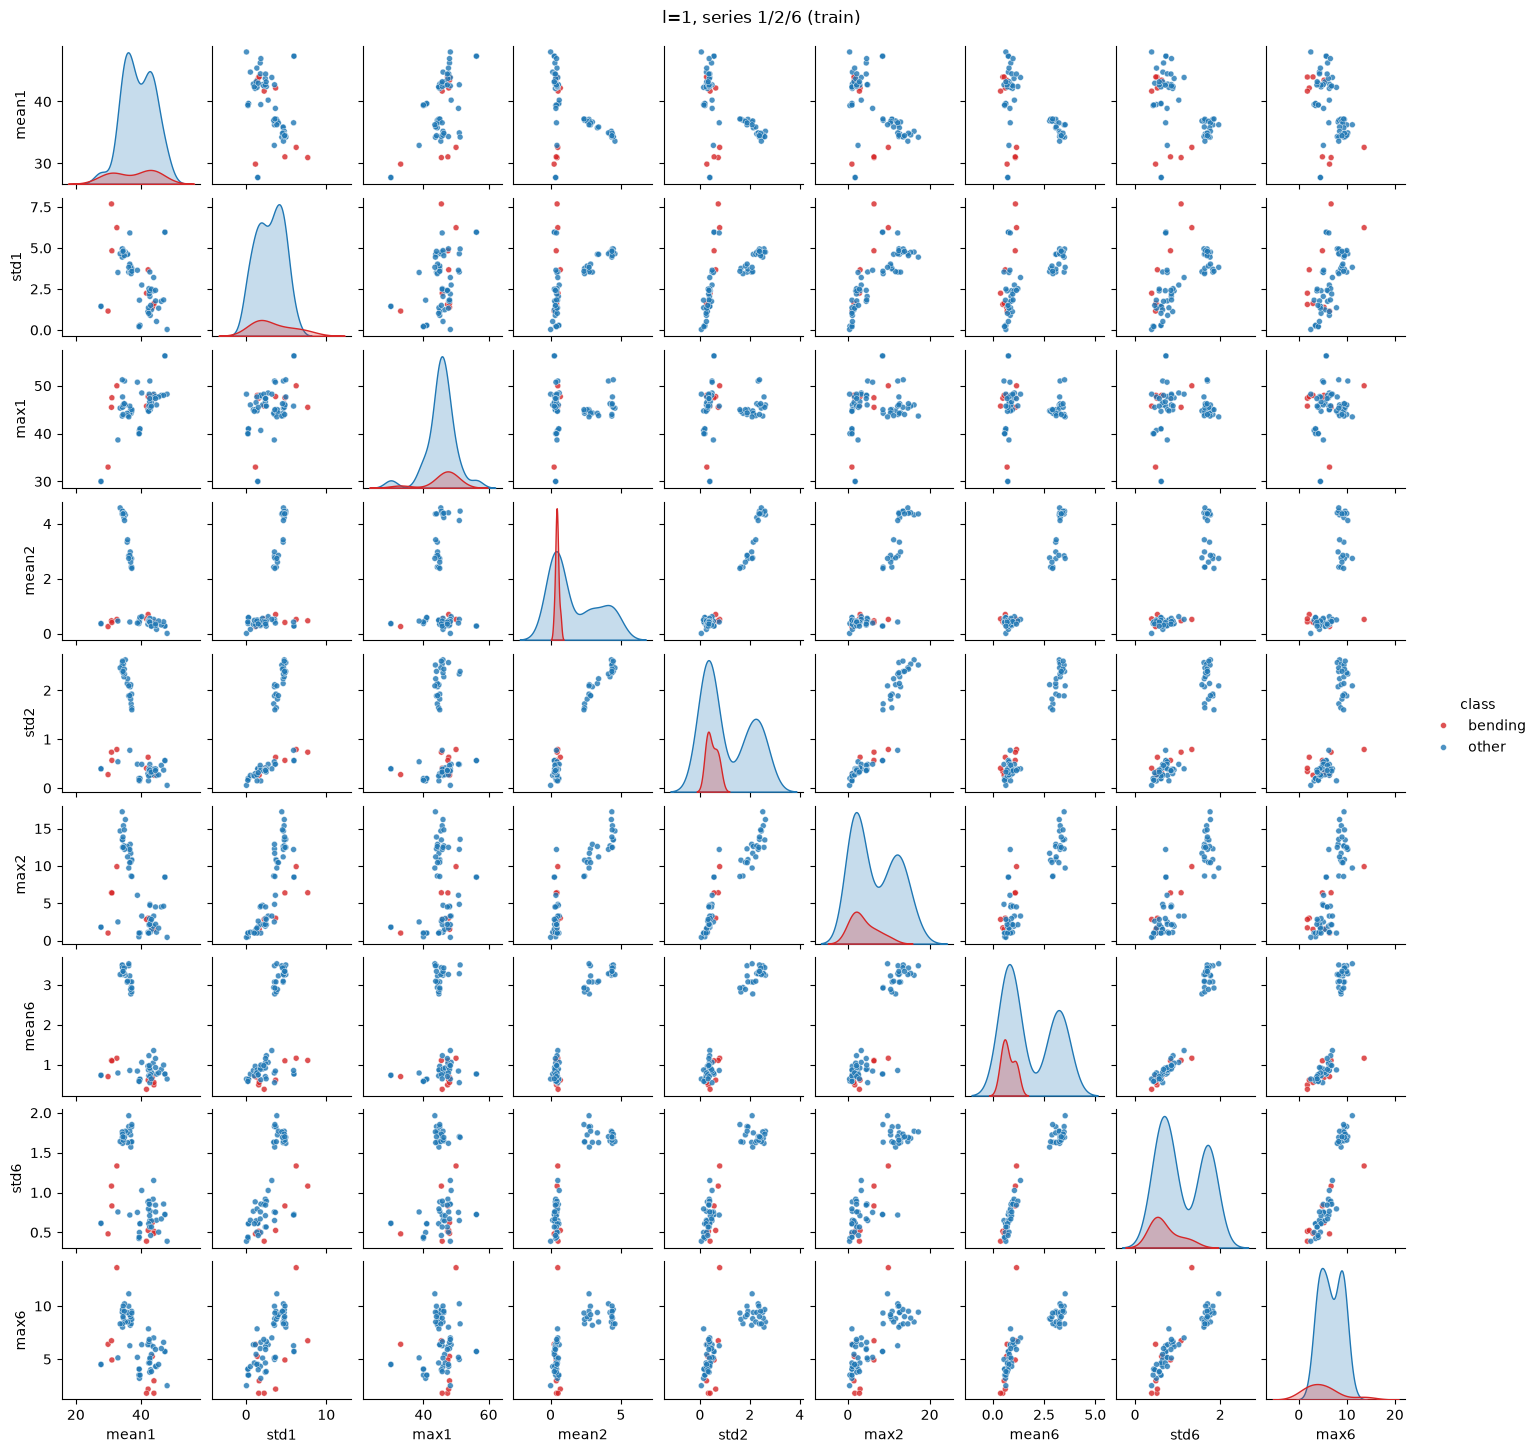

In [7]:
F1 = FEATS[1]
tr1 = F1[F1.split == 'train'].copy()
tr1['class'] = np.where(tr1.activity.str.startswith('bending'), 'bending', 'other')
cols_126 = [s + str(k) for k in (1, 2, 6) for s in SEL]

g = sns.pairplot(tr1[cols_126 + ['class']], hue='class', hue_order=['bending', 'other'],
                 palette={'bending': 'tab:red', 'other': 'tab:blue'},
                 height=1.6, plot_kws={'s': 18, 'alpha': .8})
g.figure.suptitle('l=1, series 1/2/6 (train)', y=1.01)
plt.show()

**Observations:**

> * The features of series 2 and 6 (the *variance* series `var_rss12`, `var_rss23`) split the instances into two clear groups: a high-variance cluster (large `mean2`, `std2`, `max2`, `mean6`, `std6`) made up of the **moving** activities (walking, cycling), and a low-variance cluster with all the **static** activities (lying, sitting, standing).
> * **Bending falls inside the low-variance cluster**, mixed with the other static activities. In none of the 2-D panels can bending (red) be separated from the blue points by a straight line, so series 1, 2 and 6 alone are not very good at this binary problem.
> * Within bending there are two sub-groups that show up in `mean1`: `bending2` instances have a low `mean1` (≈ 30–33) and `bending1` instances a high one (≈ 42–44), and both overlap with some static activities. The two bending postures are different, which makes "bending" a harder class than any single activity.

Footnote 4 suggests trying the other series as well. The same three statistics for series 3, 4 and 5:

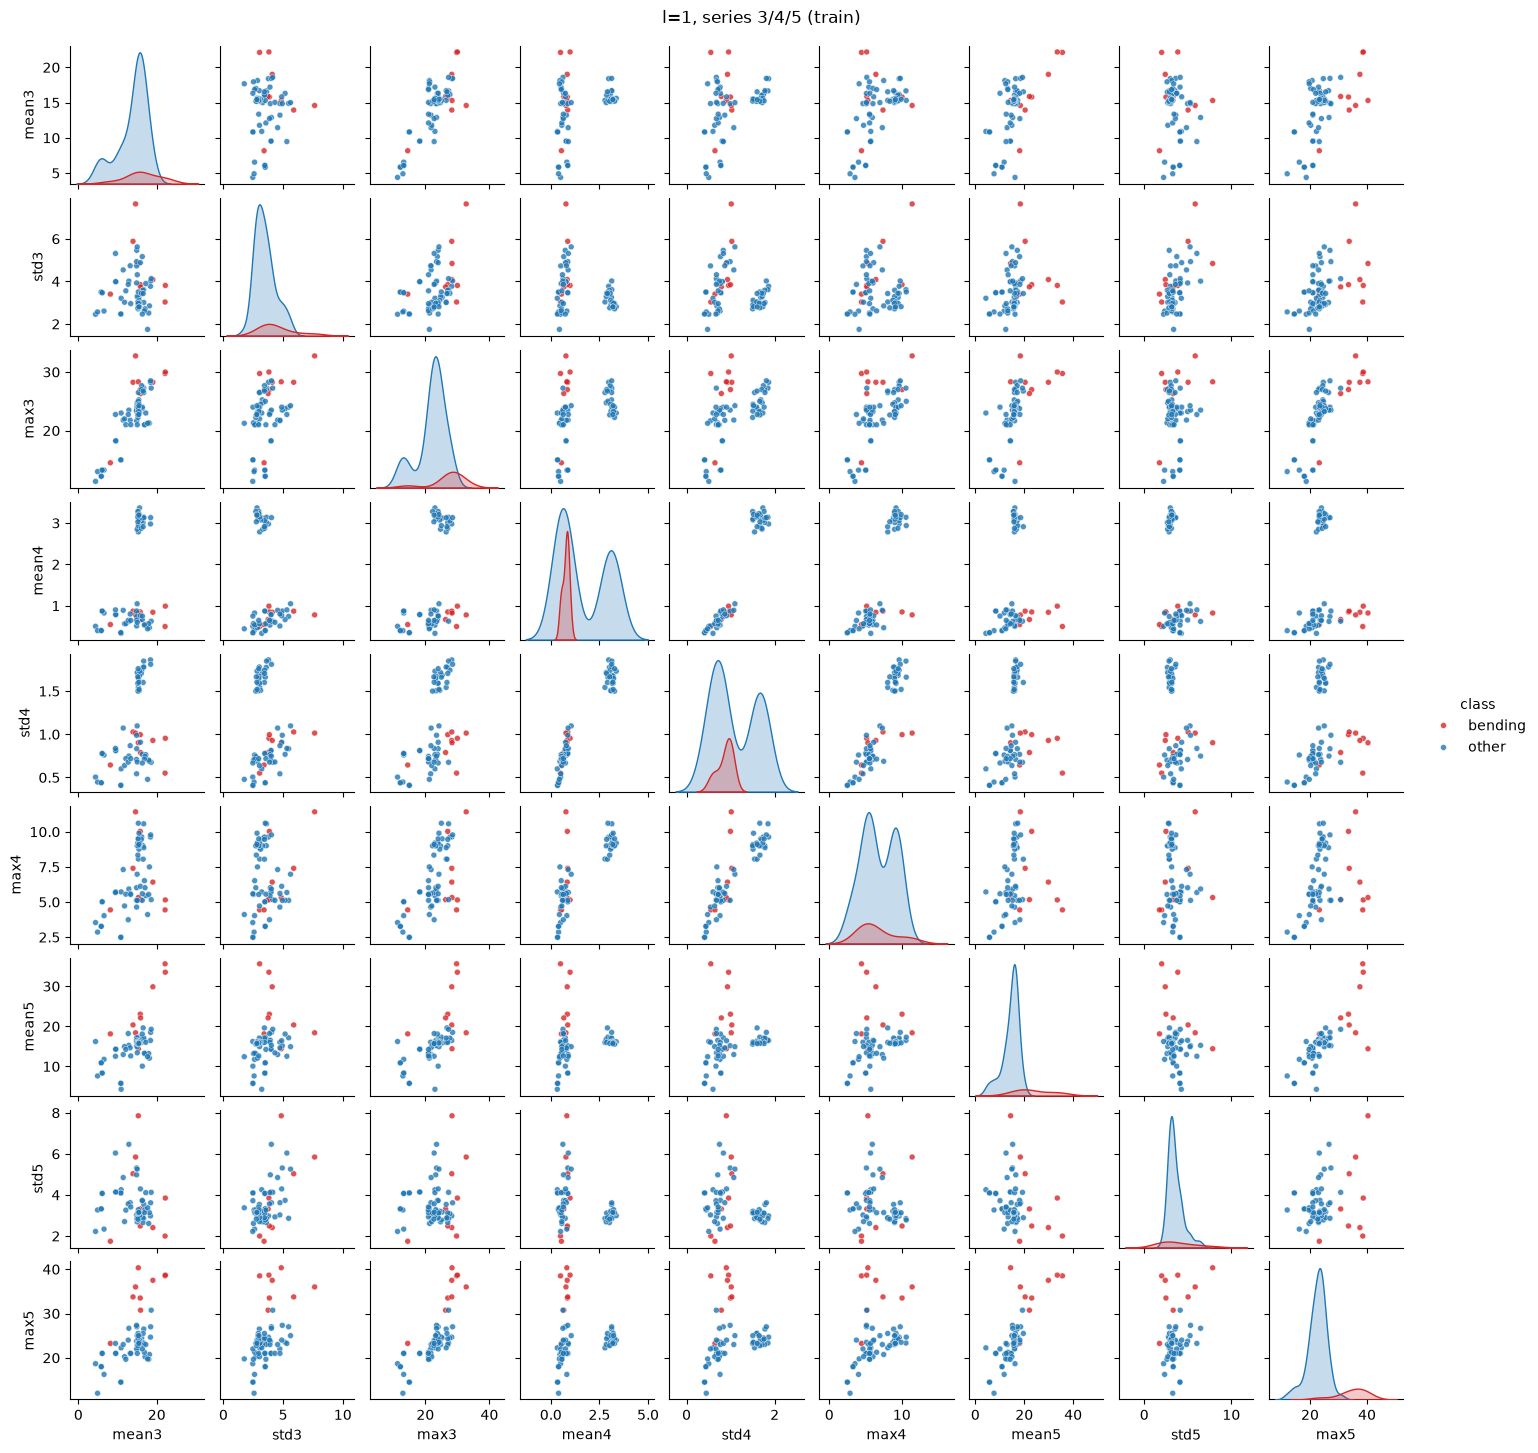

mean5          max5       
            min    max    min    max
activity                            
bending1  22.10  35.59  30.75  38.67
bending2  14.41  20.35  23.25  40.33
cycling   15.87  19.61  22.25  27.00
lying      4.30  16.21  12.00  22.25
sitting   12.54  19.27  22.00  30.75
standing  10.07  18.20  19.67  24.00
walking   15.55  16.30  22.75  25.50

In [8]:
cols_345 = [s + str(k) for k in (3, 4, 5) for s in SEL]
g = sns.pairplot(tr1[cols_345 + ['class']], hue='class', hue_order=['bending', 'other'],
                 palette={'bending': 'tab:red', 'other': 'tab:blue'},
                 height=1.6, plot_kws={'s': 18, 'alpha': .8})
g.figure.suptitle('l=1, series 3/4/5 (train)', y=1.01)
plt.show()
tr1.groupby('activity')[['mean5', 'max5']].agg(['min', 'max']).round(2)

> Series 5 (`avg_rss23`, the signal strength between the two ankle sensors) is where bending stands out: `mean5` is 22–36 for `bending1`, higher than every other activity (≤ 19.6), and `bending2` (14–20) sits at the top of the range of the other activities. This is the feature that the selection in 2(a)iii ends up using.

#### 2(a)ii Break each series into two halves (l = 2) and repeat

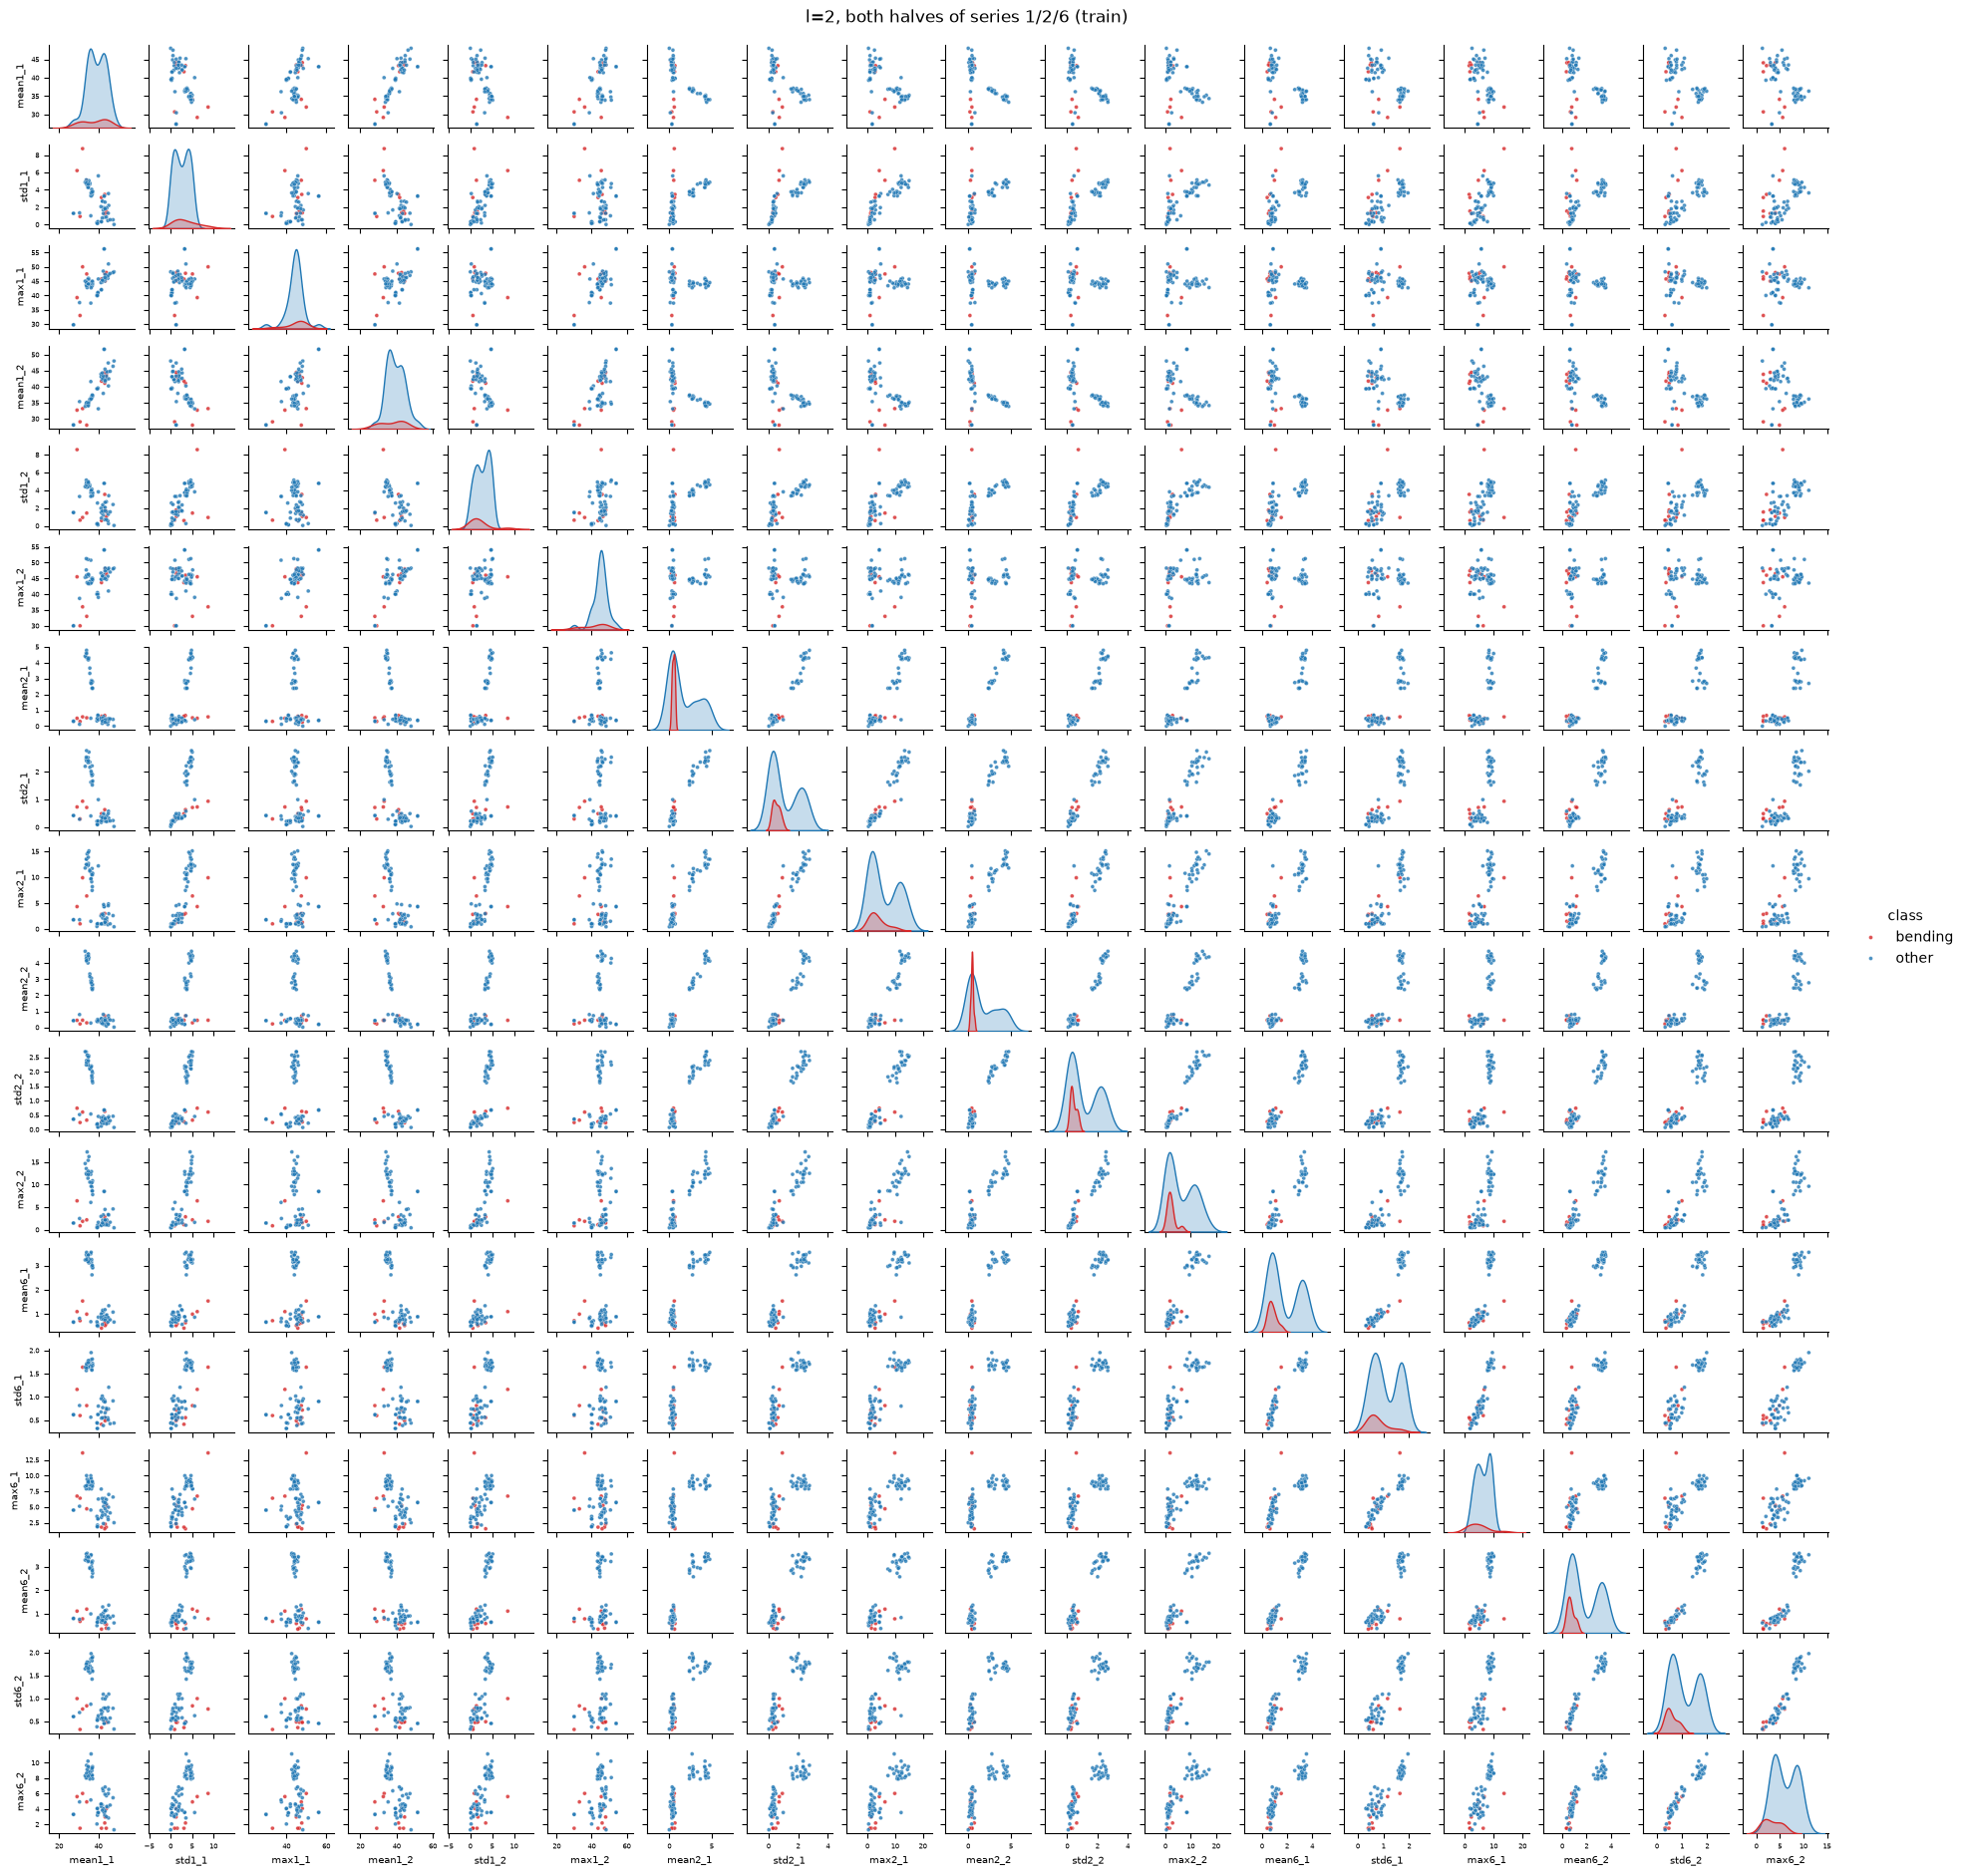

In [9]:
F2 = FEATS[2]
tr2 = F2[F2.split == 'train'].copy()
tr2['class'] = np.where(tr2.activity.str.startswith('bending'), 'bending', 'other')
cols_126_2 = [f'{s}{k}_{j}' for k in (1, 2, 6) for j in (1, 2) for s in SEL]

g = sns.pairplot(tr2[cols_126_2 + ['class']], hue='class', hue_order=['bending', 'other'],
                 palette={'bending': 'tab:red', 'other': 'tab:blue'},
                 height=1.05, plot_kws={'s': 8, 'alpha': .8})
for ax in g.axes.flat:
    ax.xaxis.label.set_size(7); ax.yaxis.label.set_size(7)
    ax.tick_params(labelsize=5)
g.figure.suptitle('l=2, both halves of series 1/2/6 (train)', y=1.005)
plt.show()

In [10]:
# do the two halves look alike?
pd.DataFrame({f'{s}{k}': [tr2[f'{s}{k}_1'].corr(tr2[f'{s}{k}_2'])] for k in (1, 2, 6) for s in SEL},
             index=['corr(half 1, half 2)']).round(3)

,mean1,std1,max1,mean2,std2,max2,mean6,std6,max6
"corr(half 1, half 2)",0.884,0.701,0.656,0.99,0.98,0.893,0.984,0.926,0.799


**Is there a considerable difference from 2(a)i?**

> No considerable difference. The panels that compare the same statistic from the two halves (e.g. `mean2_1` vs `mean2_2`) lie close to a straight line: the correlations in the table are 0.88–0.99 for the means. The activities are roughly stationary over the 2-minute recording, so the first minute looks like the second. The panels that pair different statistics or different series look like the ones in 2(a)i, duplicated for the two halves: moving vs. static activities still separate cleanly through series 2 and 6, and bending still overlaps the static activities everywhere. Splitting doubles the number of features but adds little new information. The only visible change is that `std` and especially `max` are noisier (correlation between halves 0.66–0.80 for `max1`, `max6`) because each half has only 240 samples instead of 480.

#### 2(a)iii Choosing `l` and the number of features `p` with 5-fold cross-validation

**Model.** Plain (unpenalized) logistic regression: `C = np.inf` turns off scikit-learn's built-in L2 penalty. Features are standardized (needed so that RFE can compare coefficient sizes). As footnote 5 suggests, `max_iter` is kept at 100 so the solver stops early instead of diverging when the classes are linearly separable; the resulting `ConvergenceWarning`s are expected and silenced.

**Feature selection.** Backward selection with **Recursive Feature Elimination (RFE)**, which is the alternative to p-value pruning that the homework allows. RFE repeatedly fits the model and drops the feature with the smallest |β|. Because one feature is removed per step, the sets are nested, so one RFE run down to a single feature gives the ranking for every p: the top-p ranked features are exactly what `RFE(n_features_to_select=p)` would keep. For each `l`, I try `p = 1, …, min(18·l, 30)`. Larger p is pointless here: a training fold has about 55 instances and only ~7 bending instances.

(Why not p-values? See the end of this section: the p-values are unreliable here because the classes are separable, and for `l ≥ 4` there are more features than training instances, so the full model can't even be fit.)

**The wrong way vs. the right way to cross-validate.**
* **Wrong:** run feature selection (RFE or p-value pruning) **once on the whole training set**, then cross-validate only the final logistic regression on the selected features. The selection step has already seen the validation folds' labels, so they no longer act as unseen data and the CV accuracy is optimistically biased. With 18·l up to 360 features and only 69 instances, some features will look predictive just by chance, and the wrong CV can't detect that. (ISLR §5.1.4 / ESL §7.10.2.)
* **Right:** treat every step that uses the labels (standardization, feature selection, model fitting) as part of the model and redo them **inside every fold**, using only the training part of that fold, then evaluate on the held-out fold. That is what the code below does. Splitting the series into `l` pieces is done per instance and doesn't use labels, so it can be done before the CV. `l` and `p` are then chosen by the best average validation accuracy.

**Stratified CV.** The classes are imbalanced (9 bending vs. 60 other in training). With plain 5-fold CV a fold could get 0 or 1 bending instances, so its accuracy says almost nothing about the rare class. **Stratified K-fold** splits each class separately so every fold has about the same class proportions as the full training set (here 1–2 bending + 12 other per fold). I use `StratifiedKFold(5, shuffle=True)`.

**Ties.** Many `(l, p)` pairs reach the same CV accuracy. Ties are broken toward the simplest model: smallest `p`, then smallest `l`.

In [11]:
warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)

# C=inf drops sklearn's default L2. max_iter stays at 100 on purpose (footnote 5):
# on separable folds the solver would otherwise just chase beta -> inf.
def plain_logreg():
    return LogisticRegression(C=np.inf, max_iter=100)

skf = StratifiedKFold(5, shuffle=True, random_state=SEED)

In [12]:
def rfe_cv(l):
    X, y, _, _ = split_xy(FEATS[l])
    X = X.values
    ps = range(1, min(X.shape[1], 30) + 1)
    acc = np.zeros((5, len(ps)))
    for f, (tr, va) in enumerate(skf.split(X, y)):
        # scaler only sees the train part of the fold, otherwise val data leaks in
        sc = StandardScaler().fit(X[tr])
        Xa, Xv = sc.transform(X[tr]), sc.transform(X[va])
        # one RFE run down to a single feature ranks everything; top-p is ranking_ <= p
        # (way faster than calling RFE again for every p)
        rank = RFE(plain_logreg(), n_features_to_select=1).fit(Xa, y[tr]).ranking_
        for i, p in enumerate(ps):
            keep = rank <= p
            m = plain_logreg().fit(Xa[:, keep], y[tr])
            acc[f, i] = accuracy_score(y[va], m.predict(Xv[:, keep]))
    return pd.DataFrame({'l': l, 'p': list(ps), 'cv_acc': acc.mean(0), 'cv_sd': acc.std(0)})

In [13]:
cv_rfe = pd.concat([rfe_cv(l) for l in L_VALUES], ignore_index=True)
cv_rfe.to_csv(os.path.join(OUT_DIR, 'binary_rfe_cv.csv'), index=False)
# ties: fewest features first, then smallest l
best_a = cv_rfe.sort_values(['cv_acc', 'p', 'l'], ascending=[False, True, True]).iloc[0]
L_A, P_A = int(best_a.l), int(best_a.p)
print(f'best l={L_A}, p={P_A}, CV acc {best_a.cv_acc:.4f}')

best l=3, p=1, CV acc 0.9857


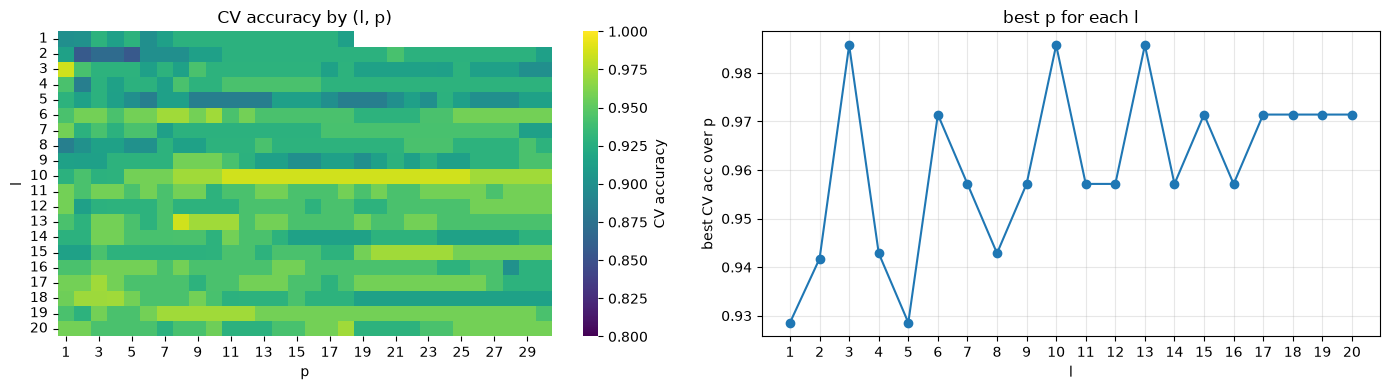

l,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
p,3.0000,21.0000,1.0000,1.0000,1.0000,7.0000,1.0000,13.0000,8.0000,11.0000,8.0000,1.0000,8.0000,3.0000,20.0000,14.0000,3.0000,4.0000,7.0000,18.0000
cv_acc,0.9286,0.9418,0.9857,0.9429,0.9286,0.9714,0.9571,0.9429,0.9571,0.9857,0.9571,0.9571,0.9857,0.9571,0.9714,0.9571,0.9714,0.9714,0.9714,0.9714
cv_sd,0.0639,0.0292,0.0286,0.0535,0.0639,0.0350,0.0571,0.0535,0.0350,0.0286,0.0571,0.0350,0.0286,0.0350,0.0350,0.0571,0.0350,0.0350,0.0350,0.0571


In [14]:
best_per_l = (cv_rfe.sort_values(['cv_acc', 'p'], ascending=[False, True])
                    .groupby('l').head(1).set_index('l').sort_index())

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(cv_rfe.pivot(index='l', columns='p', values='cv_acc'), ax=ax[0], cmap='viridis',
            vmin=.8, vmax=1, cbar_kws={'label': 'CV accuracy'})
ax[0].set_title('CV accuracy by (l, p)')
ax[1].plot(best_per_l.index, best_per_l.cv_acc, 'o-')
ax[1].set(xlabel='l', ylabel='best CV acc over p', xticks=list(L_VALUES), title='best p for each l')
ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
best_per_l[['p', 'cv_acc', 'cv_sd']].round(4).T

**Result.** The best pair is **(l, p) = (3, 1)**: split every series into 3 pieces and keep a single feature, with 5-fold CV accuracy 0.9857 (one misclassified instance out of 69). The same accuracy is reached by (l, p) = (10, 11) and (13, 8), and the tie-break picks the simplest model. The differences between values of `l` are small compared to the fold-to-fold standard deviation (0.03–0.06; one instance in a validation fold of 14 is worth 0.07), so the CV can't really tell most values of `l` apart. The data mostly say that **a very small number of features is enough**.

**Why the p-value route is not used for selection.** Footnote 6 asks for p-values of the logistic regression in each model. Below are the Wald p-values of the full (no selection) model for `l = 1`, i.e. all 18 features. They are computed from the inverse Fisher information $(X^\top W X)^{-1}$, $W = \mathrm{diag}(\hat p_i(1-\hat p_i))$, which is the same Wald test that R's `glm` / `statsmodels` report.

In [15]:
def wald_table(model, X, names):
    X = np.asarray(X, dtype=float)
    Xd = np.column_stack([np.ones(len(X)), X])
    beta = np.r_[model.intercept_, model.coef_.ravel()]
    p = model.predict_proba(X)[:, 1]
    # X'WX without building the big diagonal W, just scale each row by p(1-p)
    info = Xd.T @ (Xd * (p * (1 - p))[:, None])
    # pinv, not inv: info is close to singular once the classes separate
    # clip bc pinv can give tiny negative numbers on the diagonal -> sqrt would be nan
    se = np.sqrt(np.clip(np.diag(np.linalg.pinv(info)), 0, None))
    with np.errstate(divide='ignore', invalid='ignore'):   # se can be 0, don't spam warnings
        z = beta / se
    return pd.DataFrame({'beta': beta, 'std_err': se, 'z': z, 'p_value': 2 * stats.norm.sf(np.abs(z))},
                        index=['intercept', *names])

In [16]:
Xtr1, ytr1, _, _ = split_xy(FEATS[1])
Z1 = StandardScaler().fit_transform(Xtr1)
full1 = plain_logreg().fit(Z1, ytr1)
print('train acc, full l=1 model:', accuracy_score(ytr1, full1.predict(Z1)))
wald_table(full1, Z1, Xtr1.columns).round(3)

train acc, full l=1 model: 1.0


,beta,std_err,z,p_value
intercept,-11.648,191.772,-0.061,0.952
mean1,-4.445,246.413,-0.018,0.986
std1,1.250,467.700,0.003,0.998
max1,1.448,152.373,0.010,0.992
mean2,-0.304,495.175,-0.001,1.000
std2,-1.493,710.672,-0.002,0.998
max2,-2.503,363.825,-0.007,0.995
mean3,-3.419,318.323,-0.011,0.991
std3,-2.754,309.346,-0.009,0.993
max3,0.790,495.348,0.002,0.999


> The full model classifies the training set perfectly, and the predicted probabilities are pushed to 0 or 1. Then $\hat p_i(1-\hat p_i) \approx 0$, the Fisher information is nearly singular, and the standard errors blow up, so **every p-value is close to 1** even though the features obviously separate the classes. Pruning by "p-value > 0.05" would throw away everything. For `l ≥ 4` there are more features (72+) than training instances (69), and the full model isn't identifiable at all. That's why RFE (backward selection by |β|, inside CV) is used instead, and p-values are only reported for the final, small model in 2(a)iv.

#### 2(a)iv Final model: confusion matrix, ROC/AUC on the training data, β's and p-values
The final model uses the selected `l`, runs RFE with the selected `p` on the **whole training set**, and refits the logistic regression on those features.

In [17]:
Xtr_a, ytr_a, Xte_a, yte_a = split_xy(FEATS[L_A])
sc_a = StandardScaler().fit(Xtr_a)
Ztr_a, Zte_a = sc_a.transform(Xtr_a), sc_a.transform(Xte_a)
rfe_a = RFE(plain_logreg(), n_features_to_select=P_A).fit(Ztr_a, ytr_a)
sel_a = Xtr_a.columns[rfe_a.support_]
model_a = plain_logreg().fit(Ztr_a[:, rfe_a.support_], ytr_a)
print(f'l={L_A}, p={P_A}:', list(sel_a))

l=3, p=1: ['mean5_1']


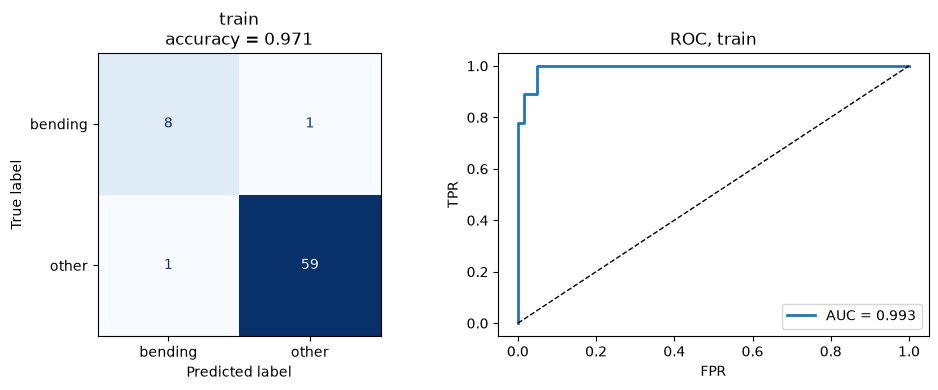

In [18]:
def show_binary(model, Z, y, title, ax_cm, ax_roc):
    prob = model.predict_proba(Z)[:, 1]
    pred = (prob >= .5).astype(int)
    acc, a = accuracy_score(y, pred), roc_auc_score(y, prob)

    cm = confusion_matrix(y, pred, labels=[1, 0])
    ConfusionMatrixDisplay(cm, display_labels=['bending', 'other']).plot(ax=ax_cm, colorbar=False, cmap='Blues')
    ax_cm.set_title(f'{title}\naccuracy = {acc:.3f}')

    fpr, tpr, _ = roc_curve(y, prob)
    ax_roc.plot(fpr, tpr, lw=2, label=f'AUC = {a:.3f}')
    ax_roc.plot([0, 1], [0, 1], 'k--', lw=1)
    ax_roc.set(xlabel='FPR', ylabel='TPR', title=f'ROC, {title}')
    ax_roc.legend(loc='lower right')
    return acc, a

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
acc_tr_a, auc_tr_a = show_binary(model_a, Ztr_a[:, rfe_a.support_], ytr_a, 'train', *ax)
plt.tight_layout(); plt.show()

In [19]:
coef_a = wald_table(model_a, Ztr_a[:, rfe_a.support_], sel_a)
coef_a.round(4)

,beta,std_err,z,p_value
intercept,-10.0560,7.0781,-1.4207,0.1554
mean5_1,16.7156,12.7394,1.3121,0.1895


*(β's are on the standardized scale: β_j is the change in log-odds of bending for a one-standard-deviation increase of feature j.)*

#### 2(a)v Test set
The test series are split into the same `l` pieces, the features are extracted from the test series, standardized with the **training** mean/std, and the same selected features are used.

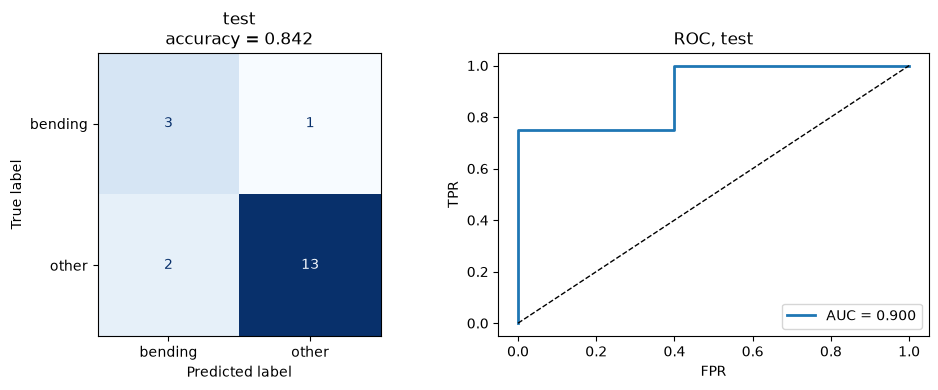

,5-fold CV accuracy,test accuracy,test AUC
"logistic + RFE (l=3, p=1)",0.9857,0.8421,0.9


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
acc_te_a, auc_te_a = show_binary(model_a, Zte_a[:, rfe_a.support_], yte_a, 'test', *ax)
plt.tight_layout(); plt.show()
pd.DataFrame({'5-fold CV accuracy': [best_a.cv_acc], 'test accuracy': [acc_te_a], 'test AUC': [auc_te_a]},
             index=[f'logistic + RFE (l={L_A}, p={P_A})']).round(4)

In [21]:
te_a = FEATS[L_A].query("split == 'test'")[['activity', 'file']].copy()
te_a[list(sel_a)] = Xte_a[sel_a].values
te_a['P(bending)'] = model_a.predict_proba(Zte_a[:, rfe_a.support_])[:, 1]
te_a['true'] = np.where(yte_a == 1, 'bending', 'other')
te_a['predicted'] = np.where(te_a['P(bending)'] >= .5, 'bending', 'other')

# misses in red
te_a.round(3).style.apply(lambda r: ['background-color: #f8d0d0' if r.true != r.predicted else ''] * len(r), axis=1)

,activity,file,mean5_1,P(bending),true,predicted
0,bending1,1,34.051000,1.000000,bending,bending
1,bending1,2,33.483000,1.000000,bending,bending
7,bending2,1,25.928000,1.000000,bending,bending
8,bending2,2,17.339000,0.007000,bending,other
13,cycling,1,19.118000,0.571000,other,bending
14,cycling,2,18.779000,0.329000,other,other
15,cycling,3,19.793000,0.907000,other,bending
28,lying,1,9.313000,0.000000,other,other
29,lying,2,7.792000,0.000000,other,other
30,lying,3,3.784000,0.000000,other,other


**Test vs. cross-validation.** The test accuracy is **0.842** (16 of 19), clearly below the CV accuracy of **0.986**; the test AUC is 0.90 (train AUC 0.993). The three errors (red rows above):
* `bending2/dataset2` is missed: its `mean5_1` (17.3) is lower than every bending instance in the training set (min 18.6) and falls among sitting/cycling.
* `cycling/dataset1` and `cycling/dataset3` are called bending: their `mean5_1` (19.1, 19.8) is at the top of the cycling range, where the `bending2` training instances also are.

Why the gap:
1. **The test set is tiny.** Each error costs 5.3 percentage points, so 0.842 vs. 0.986 is a difference of about 3 instances.
2. **The CV estimate is optimistic** because `(l, p)` was picked as the *maximum* over ≈ 590 CV scores, many of them within one instance of each other. The winner is partly the one that got lucky on these particular folds (selection bias), so its CV score overstates its true accuracy. An honest estimate of that would need nested CV.
3. **One feature is fragile.** A single threshold on `mean5_1` works well for `bending1`, but `bending2` overlaps cycling and sitting on this feature, so any `bending2`/cycling instance near the boundary can go either way.

#### 2(a)vi Are the classes well separated enough to make logistic regression unstable?

In [22]:
# near hard-margin SVM: 100% train accuracy means linearly separable
def separable(X, y):
    # huge C = basically no slack allowed, so it only hits 100% if a line can split them
    Z = StandardScaler().fit_transform(X)
    return LinearSVC(C=1e6, max_iter=200000).fit(Z, y).score(Z, y) == 1.0

print(pd.Series({
    f'selected (l={L_A}, p={P_A})': separable(Xtr_a[sel_a], ytr_a),
    'l=1, mean1 only': separable(Xtr1[['mean1']], ytr1),
    'l=1, all 18': separable(Xtr1, ytr1),
}, name='separable?'), '\n')

# do the coefficients keep growing if the solver runs longer?
rows = []
for it in [10, 100, 1000, 10000]:
    m = LogisticRegression(C=np.inf, max_iter=it).fit(Ztr_a[:, rfe_a.support_], ytr_a)
    rows.append([it, *m.intercept_, *m.coef_.ravel()])
pd.DataFrame(rows, columns=['max_iter', 'intercept', *sel_a]).set_index('max_iter').round(2)

selected (l=3, p=1)    False
l=1, mean1 only        False
l=1, all 18             True
Name: separable?, dtype: bool 



,intercept,mean5_1
max_iter,,
10,-7.62,12.33
100,-10.06,16.72
1000,-10.06,16.72
10000,-10.06,16.72


**Yes, at the scale of the full feature sets the classes are separable enough to cause instability**, though the final 1-feature model happens to avoid it:

* With all 18 features at `l = 1` the training data are **linearly separable** (the hard-margin SVM gets 100%), and for every `l ≥ 4` there are more features than training instances, so the data are always separable. Then the logistic regression MLE **does not exist**: the likelihood keeps increasing as ‖β‖ → ∞, the solver never converges, the coefficients just grow with the number of iterations, and the standard errors explode (all the p-values ≈ 1 in the full `l = 1` model in 2(a)iii). This is why `max_iter` was capped (footnote 5). Many of the RFE models with larger `p` evaluated in the CV were fit on separable folds like this.
* The chosen model uses only `mean5_1`, which is **not** separable (1 bending and 1 other instance overlap), so its coefficients converge: the fit is identical for `max_iter` = 100, 1 000 and 10 000. It is close to separable, though: the slope is very steep (16.7 per standard deviation), which makes the standard error large and the Wald p-value of `mean5_1` 0.19, even though the feature alone gives 97% training accuracy. That is the classic symptom of (quasi-)separation (Hauck–Donner effect).
* An L1 penalty (2(b)) is the standard fix: it keeps the coefficients finite even when the classes are separable.

#### 2(a)vii Class imbalance and case-control sampling

**Is there class imbalance?** Yes. The training set has 9 bending vs. 60 other (13% bending) and the test set 4 vs. 15. The confusion matrices show the effect: the rare class gets the higher error rate. On the training set 1 of 9 bending instances is missed (11%) vs. 1 of 60 others (1.7%); on the test set 1 of 4 bending (25%) vs. 2 of 15 others (13%). A classifier that always answers "other" would already get 87% accuracy, so accuracy alone is a weak measure here.

**Case-control sampling** (ISLR §4.3.5 / lecture): keep **all** cases (bending) and draw only a random subset of the controls (others), so that the sample is balanced. Fitting logistic regression on such a sample gives correct slope estimates β₁,…,β_p, but a wrong intercept, because the sample's proportion of cases π̃ differs from the population proportion π. The intercept is corrected with

$$\hat\beta_0^{*} = \hat\beta_0 + \log\frac{\pi}{1-\pi} - \log\frac{\tilde\pi}{1-\tilde\pi}.$$

Here π = 9/69 (fraction of bending in the training set) and I sample 9 controls for the 9 cases, so π̃ = 0.5. The same `l` and features as in 2(a)iv are used. Because 18 points is a very small sample, the draw is repeated 100 times and the coefficients are averaged (each fit is a valid case-control estimate, and averaging only reduces the variance coming from which controls were drawn).

In [23]:
rng = np.random.default_rng(SEED)
Zsel = Ztr_a[:, rfe_a.support_]
cases, controls = np.flatnonzero(ytr_a == 1), np.flatnonzero(ytr_a == 0)
pi = ytr_a.mean()
logit = lambda q: np.log(q / (1 - q))

coefs, ints = [], []
for _ in range(100):
    # all 9 bending + 9 random others -> 50/50 sample
    idx = np.r_[cases, rng.choice(controls, size=len(cases), replace=False)]
    m = plain_logreg().fit(Zsel[idx], ytr_a[idx])
    coefs.append(m.coef_.ravel())
    # the sample's case rate isn't the population's, so shift the intercept back
    ints.append(m.intercept_[0] + logit(pi) - logit(ytr_a[idx].mean()))

# fit anything just to get a working predict_proba, then swap in the averaged params
model_cc = plain_logreg().fit(Zsel, ytr_a)
model_cc.coef_ = np.mean(coefs, axis=0)[None, :]
model_cc.intercept_ = np.array([np.mean(ints)])

In [24]:
print(f'pi = {pi:.4f}, sample pi = 0.5, intercept shift = {np.log(pi / (1 - pi)):.4f}')
pd.DataFrame({'full-data model': np.r_[model_a.intercept_, model_a.coef_.ravel()],
              'case-control (adjusted)': np.r_[model_cc.intercept_, model_cc.coef_.ravel()]},
             index=['intercept'] + list(sel_a)).round(3)

pi = 0.1304, sample pi = 0.5, intercept shift = -1.8971


,full-data model,case-control (adjusted)
intercept,-10.056,-35.333
mean5_1,16.716,70.029


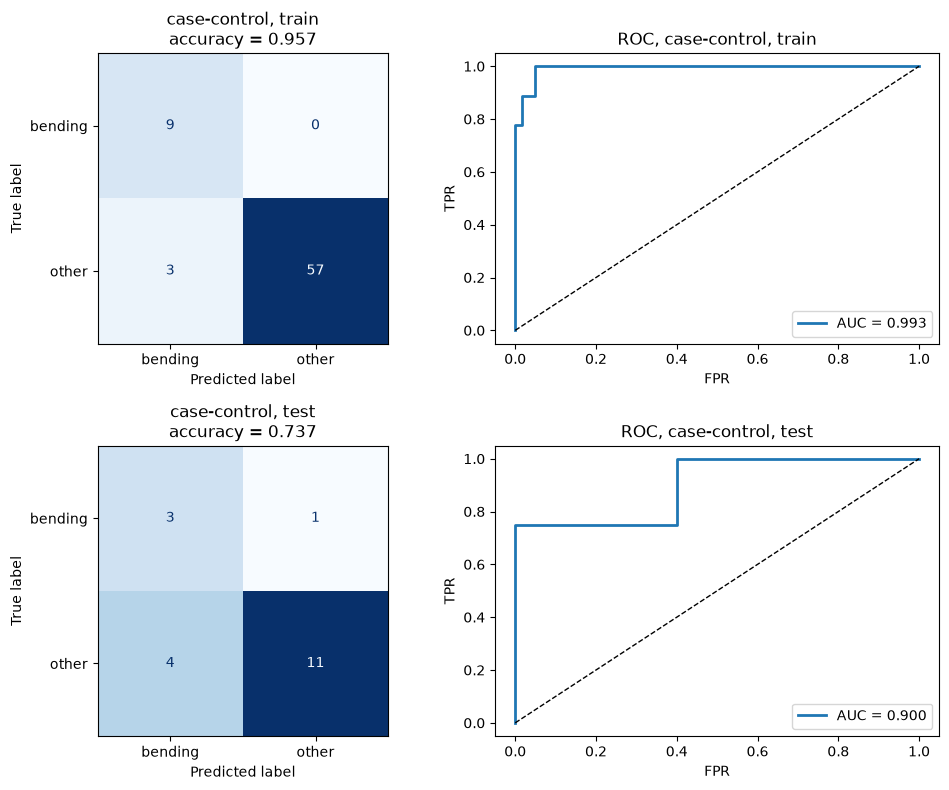

In [25]:
fig, ax = plt.subplots(2, 2, figsize=(10, 8))
acc_tr_cc, auc_tr_cc = show_binary(model_cc, Zsel, ytr_a, 'case-control, train', ax[0, 0], ax[0, 1])
acc_te_cc, auc_te_cc = show_binary(model_cc, Zte_a[:, rfe_a.support_], yte_a, 'case-control, test', ax[1, 0], ax[1, 1])
plt.tight_layout(); plt.show()

**Case-control results.**

| | full-data model (2(a)iv) | case-control, adjusted |
|---|---|---|
| train confusion (bending: TP / FN, other: FP / TN) | 8 / 1, 1 / 59 | 9 / 0, 3 / 57 |
| train accuracy / AUC | 0.971 / 0.993 | 0.957 / 0.993 |
| test confusion | 3 / 1, 2 / 13 | 3 / 1, 4 / 11 |
| test accuracy / AUC | 0.842 / 0.900 | 0.737 / 0.900 |

* **The AUC does not change at all.** With one feature, both models give a probability that increases with `mean5_1`, so they rank the instances in the same order. ROC/AUC depend only on that order. Case-control sampling and the intercept correction only move the **decision threshold** (from a standardized `mean5_1` of 0.60 to 0.50).
* The lower threshold predicts bending more often: the case-control model finds all 9 training bending instances (0 false negatives), at the cost of more false positives on both sets, so the test accuracy goes down.
* The slope estimate is much steeper (70 vs. 17). With only 18 points per subsample, many subsamples are perfectly separable on `mean5_1`, so their fits stop at `max_iter` with very large coefficients (the separation problem of 2(a)vi again). The averaged model is close to a step function.
* Conclusion: case-control sampling is mainly a tool for saving computation when there are huge numbers of controls. Here it throws away 51 of 60 controls from an already tiny data set and doesn't improve the classifier. With this mild imbalance, keeping all the data and moving the threshold (or using class weights) is a better choice.

### 2(b) Binary Classification Using L1-penalized logistic regression

#### 2(b)i Cross-validating both `l` and `C`
Instead of RFE / p-values, the L1 penalty does the feature selection: it shrinks some β's to exactly 0. The objective is
$$\min_{\beta}\; \|\beta\|_1 + C\sum_i \log\!\left(1 + e^{-y_i(\beta_0 + x_i^\top\beta)}\right),$$
so **C = 1/λ** is the budget: small C = strong penalty = few features. Features are standardized (inside each fold, via a `Pipeline`) because the L1 penalty treats all coefficients on the same scale. The solver is **liblinear** (as recommended).

For each `l = 1, …, 20`, `GridSearchCV` runs the same stratified 5-fold CV over 40 values of C in [10⁻², 10³]. The pipeline makes this the *right* way: scaling and the L1 selection are refit inside every fold. The best `(l, C)` has the highest mean CV accuracy; ties go to the smallest `l`, and inside one `l` to the smallest C (the sparsest model).

In [26]:
C_GRID = np.logspace(-2, 3, 40)

def l1_pipe():
    lr = LogisticRegression(l1_ratio=1.0, solver='liblinear', max_iter=10000, random_state=SEED)
    return Pipeline([('sc', StandardScaler()), ('lr', lr)])

rows = []
for l in L_VALUES:
    X, y, _, _ = split_xy(FEATS[l])
    # scaler is inside the pipeline so GridSearchCV refits it per fold (no leakage)
    gs = GridSearchCV(l1_pipe(), {'lr__C': C_GRID}, cv=skf, scoring='accuracy', n_jobs=-1).fit(X, y)
    rows.append({'l': l, 'best_C': gs.best_params_['lr__C'], 'cv_acc': gs.best_score_,
                 'cv_sd': gs.cv_results_['std_test_score'][gs.best_index_],
                 'nonzero_coefs': int((gs.best_estimator_['lr'].coef_ != 0).sum())})
cv_l1 = pd.DataFrame(rows).set_index('l')

# stable sort so ties keep the smallest l
best_b = cv_l1.sort_values('cv_acc', ascending=False, kind='stable').iloc[0]
L_B, C_B = int(best_b.name), best_b.best_C
print(f'best l={L_B}, C={C_B:.4g}, CV acc {best_b.cv_acc:.4f}')
cv_l1.round(4).T

best l=12, C=0.6236, CV acc 0.9857


l,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
best_C,2.0309,2.0309,0.2572,0.6236,0.4642,0.2572,0.2572,70.1704,0.6236,412.4626,4.9239,0.6236,0.6236,0.2572,0.3455,70.1704,0.6236,0.6236,0.6236,1.1253
cv_acc,0.9714,0.9571,0.9714,0.9714,0.9418,0.9571,0.9418,0.9429,0.9275,0.9714,0.9714,0.9857,0.9714,0.9714,0.9571,0.9571,0.9714,0.9857,0.9857,0.9857
cv_sd,0.0571,0.0571,0.0350,0.0350,0.0292,0.0350,0.0292,0.0286,0.0022,0.0350,0.0350,0.0286,0.0350,0.0350,0.0350,0.0350,0.0350,0.0286,0.0286,0.0286
nonzero_coefs,7.0000,10.0000,3.0000,9.0000,9.0000,3.0000,4.0000,22.0000,12.0000,30.0000,11.0000,5.0000,7.0000,6.0000,8.0000,23.0000,8.0000,8.0000,8.0000,8.0000


5 of 216 non-zero, intercept -2.6300


,beta (standardized)
max1_7,-0.5449
std3_3,0.0282
mean5_2,1.9375
mean5_11,0.2071
max6_11,-0.5228


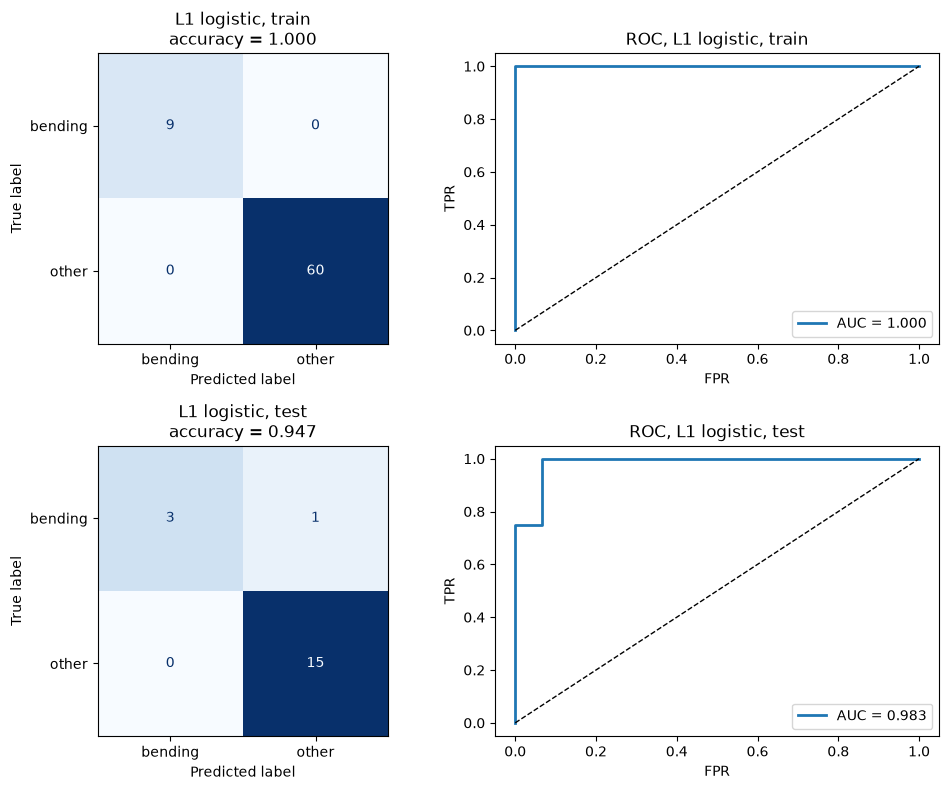

In [27]:
cv_l1.to_csv(os.path.join(OUT_DIR, 'binary_l1_cv.csv'))

Xtr_b, ytr_b, Xte_b, yte_b = split_xy(FEATS[L_B])
model_b = l1_pipe().set_params(lr__C=C_B).fit(Xtr_b, ytr_b)
coef_b = pd.Series(model_b['lr'].coef_.ravel(), index=Xtr_b.columns)
nz = coef_b[coef_b != 0]
print(f'{len(nz)} of {len(coef_b)} non-zero, intercept {model_b["lr"].intercept_[0]:.4f}')
display(nz.to_frame('beta (standardized)').round(4))

fig, ax = plt.subplots(2, 2, figsize=(10, 8))
acc_tr_b, auc_tr_b = show_binary(model_b, Xtr_b, ytr_b, 'L1 logistic, train', ax[0, 0], ax[0, 1])
acc_te_b, auc_te_b = show_binary(model_b, Xte_b, yte_b, 'L1 logistic, test', ax[1, 0], ax[1, 1])
plt.tight_layout(); plt.show()

#### 2(b)ii L1 penalty vs. variable selection (RFE / p-values)

In [28]:
cmp_b = pd.DataFrame({
    'l': [L_A, L_B],
    'features used': [P_A, len(nz)],
    '5-fold CV accuracy': [best_a.cv_acc, best_b.cv_acc],
    'train accuracy': [acc_tr_a, acc_tr_b],
    'test accuracy': [acc_te_a, acc_te_b],
    'test AUC': [auc_te_a, auc_te_b],
}, index=['logistic + RFE (2a)', 'L1-penalized logistic (2b)'])
cmp_b.round(4)

,l,features used,5-fold CV accuracy,train accuracy,test accuracy,test AUC
logistic + RFE (2a),3,1,0.9857,0.971,0.8421,0.9000
L1-penalized logistic (2b),12,5,0.9857,1.000,0.9474,0.9833


**Which performs better?** The **L1-penalized** model. Both reach the same CV accuracy (0.986), but the L1 model classifies the training set perfectly and makes only **one test error** (test accuracy 0.947 vs. 0.842, test AUC 0.983 vs. 0.900). The one mistake is the same hard instance, `bending2/dataset2`. The L1 model keeps 5 of 216 features: the dominant one is `mean5_2` (the mean of series 5 again, now over the 2nd twelfth of the recording), plus small weights on `max1_7`, `std3_3`, `mean5_11` and `max6_11`. Using a few features from different series makes it less fragile than the single-threshold RFE model. With only 19 test instances, the difference is 2 instances, so it's suggestive rather than conclusive.

**Which is easier to implement?** Also the **L1** model. It is one `Pipeline` + `GridSearchCV` over C for each `l`; the selection happens inside the fit, and the coefficients stay finite even when the classes are separable. The p-value / backward-selection approach needs a custom CV loop so that selection is redone inside each fold, a separate computation of the p-values (scikit-learn doesn't give them), and it breaks down here anyway: with separation the p-values are meaningless, and for `l ≥ 4` the full model can't be fit (p > n).

### 2(c) Multi-class Classification (The Realistic Case)

#### 2(c)i L1-penalized multinomial logistic regression
All 7 activities are now separate classes. The model is a multinomial (softmax) logistic regression with an L1 penalty, fit with the **saga** solver (liblinear can only do one-vs-rest; newer scikit-learn versions support L1 for the true multinomial loss with saga). `l` and `C` are chosen exactly as in 2(b)i: stratified 5-fold CV over a grid of C for every `l`, with scaling inside the pipeline.

*Note:* `bending2` has only 4 training instances, so with 5 folds one fold gets no `bending2` instance; scikit-learn warns about this. Stratification still keeps every other class (and both bending classes as far as possible) evenly spread.

In [29]:
warnings.filterwarnings('ignore', message='The least populated class')
C_GRID_M = np.logspace(-1, 3, 12)

def mn_pipe():
    lr = LogisticRegression(l1_ratio=1.0, solver='saga', max_iter=5000, tol=1e-3, random_state=SEED)
    return Pipeline([('sc', StandardScaler()), ('lr', lr)])

rows = []
for l in L_VALUES:
    X, y, _, _ = split_xy(FEATS[l], target='multi')
    gs = GridSearchCV(mn_pipe(), {'lr__C': C_GRID_M}, cv=skf, scoring='accuracy', n_jobs=-1).fit(X, y)
    rows.append({'l': l, 'best_C': gs.best_params_['lr__C'], 'cv_acc': gs.best_score_,
                 'cv_sd': gs.cv_results_['std_test_score'][gs.best_index_]})
cv_mn = pd.DataFrame(rows).set_index('l')

best_c = cv_mn.sort_values('cv_acc', ascending=False, kind='stable').iloc[0]
L_C, C_C = int(best_c.name), best_c.best_C
print(f'best l={L_C}, C={C_C:.4g}, CV acc {best_c.cv_acc:.4f}')
cv_mn.round(4).T

best l=17, C=0.5337, CV acc 0.9000


l,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
best_C,1.2328,187.3817,0.2310,6.5793,6.5793,6.5793,15.1991,81.1131,15.1991,2.8480,81.1131,81.1131,15.1991,35.1119,35.1119,0.5337,0.5337,1.2328,187.3817,187.3817
cv_acc,0.8989,0.8560,0.8407,0.8429,0.8571,0.8571,0.8703,0.8132,0.8571,0.8132,0.8857,0.8857,0.8429,0.8275,0.8560,0.8143,0.9000,0.8429,0.8560,0.8714
cv_sd,0.0342,0.0773,0.0530,0.1050,0.0904,0.0782,0.0523,0.0711,0.1010,0.0843,0.0969,0.0728,0.0948,0.0552,0.0435,0.0969,0.0571,0.0833,0.0435,0.0700


**Confusion matrices and ROC curves for more than two classes.**
* The **confusion matrix** generalizes directly: a K × K table where entry (i, j) counts instances of true class i predicted as class j. The diagonal holds the correct predictions; off-diagonal cells show which classes get confused with which.
* A **ROC curve** needs one score and two classes, so for K classes it's built **one-vs-rest**: for each class k, treat k as positive and all other classes as negative, use the predicted probability $\hat P(Y = k \mid x)$ as the score, and draw a ROC curve and AUC per class. These K curves are summarized by
  * **macro-average**: the average of the K per-class AUCs (every class counts equally), and
  * **micro-average**: pool all K × n (instance, class) decisions into one binary problem and compute one ROC/AUC (bigger classes count more).

  (The R package `pROC` uses the Hand & Till generalization, the average AUC over all pairs of classes, which is reported too.)

With only 2–3 test instances per class, each test ROC curve has very few steps, so the per-class AUCs are coarse.

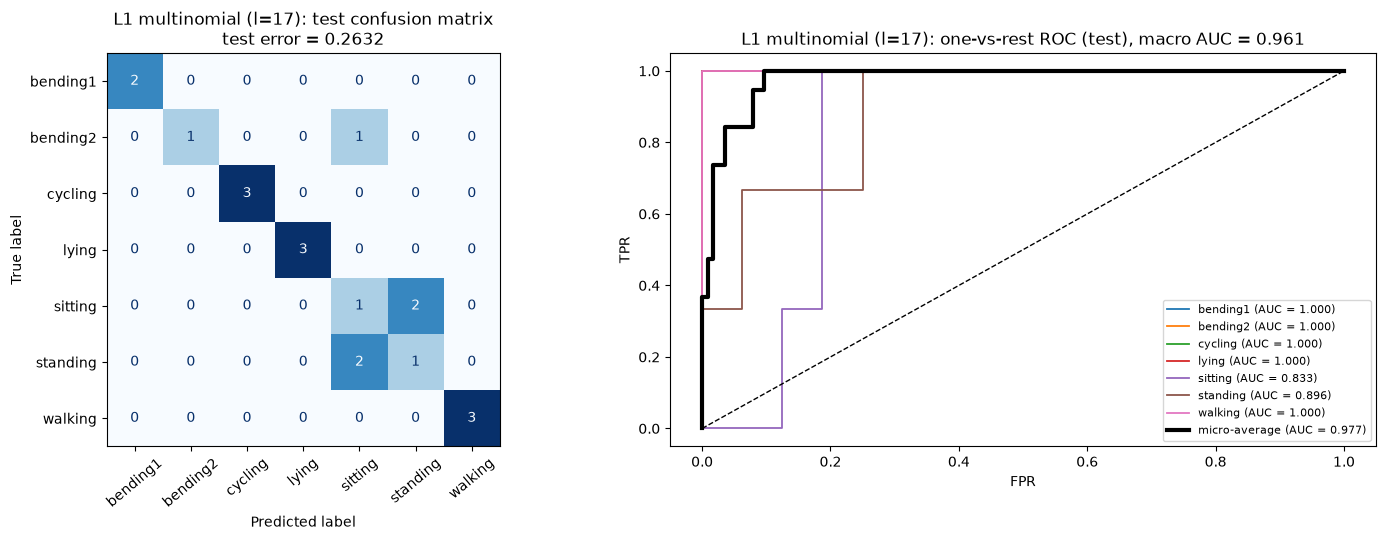

79 of 306 features have a non-zero coef for some class


test error       0.2632
train error      0.0000
micro AUC        0.9774
macro AUC        0.9613
Hand-Till AUC    0.9616
dtype: float64

In [30]:
def show_multi(model, Xtr, ytr, Xte, yte, title):
    classes = model.classes_
    pred, prob = model.predict(Xte), model.predict_proba(Xte)
    err = 1 - accuracy_score(yte, pred)

    fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
    ConfusionMatrixDisplay(confusion_matrix(yte, pred, labels=classes), display_labels=classes).plot(
        ax=ax[0], colorbar=False, cmap='Blues', xticks_rotation=40)
    ax[0].set_title(f'{title}: test confusion matrix\ntest error = {err:.4f}')

    # one-vs-rest curve per class, plus micro (pooled) and macro (mean of per-class AUCs)
    Y = label_binarize(yte, classes=classes)
    aucs = []
    for k, c in enumerate(classes):
        fpr, tpr, _ = roc_curve(Y[:, k], prob[:, k])
        aucs.append(auc(fpr, tpr))
        ax[1].plot(fpr, tpr, lw=1.3, label=f'{c} (AUC = {aucs[-1]:.3f})')
    # micro = flatten everything into one big yes/no problem
    fpr, tpr, _ = roc_curve(Y.ravel(), prob.ravel())
    micro, macro = auc(fpr, tpr), np.mean(aucs)
    ax[1].plot(fpr, tpr, 'k-', lw=3, label=f'micro-average (AUC = {micro:.3f})')
    ax[1].plot([0, 1], [0, 1], 'k--', lw=1)
    ax[1].set(xlabel='FPR', ylabel='TPR', title=f'{title}: one-vs-rest ROC (test), macro AUC = {macro:.3f}')
    ax[1].legend(fontsize=8, loc='lower right')
    plt.tight_layout(); plt.show()

    return {'test error': err, 'train error': 1 - accuracy_score(ytr, model.predict(Xtr)),
            'micro AUC': micro, 'macro AUC': macro,
            'Hand-Till AUC': roc_auc_score(yte, prob, multi_class='ovo', labels=classes)}

cv_mn.to_csv(os.path.join(OUT_DIR, 'multiclass_l1_cv.csv'))

Xtr_c, ytr_c, Xte_c, yte_c = split_xy(FEATS[L_C], target='multi')
model_c = mn_pipe().set_params(lr__C=C_C).fit(Xtr_c, ytr_c)
res_c = show_multi(model_c, Xtr_c, ytr_c, Xte_c, yte_c, f'L1 multinomial (l={L_C})')
nz_c = int((np.abs(model_c['lr'].coef_).sum(0) != 0).sum())
print(f'{nz_c} of {Xtr_c.shape[1]} features have a non-zero coef for some class')
pd.Series(res_c).round(4)

**Results.** The best `l` is **17** (C ≈ 0.53, CV accuracy 0.900) and the **test error is 0.263** (5 of 19 wrong).
* Bending1, cycling, lying and walking are classified perfectly, and their one-vs-rest AUCs are 1.
* Almost all errors are **sitting ↔ standing** (2 sitting → standing, 2 standing → sitting); these two static postures produce very similar signal strengths. The other error is one `bending2` predicted as sitting.
* The training error is 0 and the model keeps 79 of 306 features, so with 69 training instances it overfits somewhat. The CV accuracy across `l` is noisy (0.81–0.90 with fold SDs up to 0.10), and `l = 1` scores almost the same (0.899), so the choice of `l = 17` isn't much better than the others.
* The probabilities still rank the classes well (micro AUC 0.977, macro 0.961): the errors are mostly close calls between sitting and standing.

#### 2(c)ii Naïve Bayes with Gaussian and Multinomial likelihoods

Naïve Bayes assumes the features are independent given the class: $P(x \mid Y = k) = \prod_j P(x_j \mid Y = k)$. The two variants differ in how each $P(x_j \mid Y=k)$ is modelled:
* **Gaussian NB:** each feature is normal within each class, with a class-specific mean and variance. Scaling doesn't matter, so raw features are used. `var_smoothing` (a small amount added to every variance for numerical stability) is cross-validated.
* **Multinomial NB:** the features are treated as counts/frequencies of a multinomial distribution, $P(x \mid Y = k) \propto \prod_j \theta_{kj}^{x_j}$. This needs non-negative features, so every feature is min-max scaled to [0, 1] inside the pipeline (values of the test set outside the training range are clipped). The Laplace/Lidstone smoothing `alpha` is cross-validated.

Both use the class frequencies of the training set as the prior P(Y = k). `l` and the hyperparameter are chosen by the same stratified 5-fold CV as before.

In [31]:
NB_MODELS = {
    'Gaussian NB': (Pipeline([('nb', GaussianNB())]),
                    {'nb__var_smoothing': np.logspace(-11, -1, 11)}),
    # MultinomialNB wants non-negative "counts", so squash everything into [0, 1] first
    'Multinomial NB': (Pipeline([('sc', MinMaxScaler(clip=True)), ('nb', MultinomialNB())]),
                       {'nb__alpha': np.logspace(-3, 1, 9)}),
}

cv_nb, best_nb = {}, {}
for name, (pipe, grid) in NB_MODELS.items():
    param = next(iter(grid))
    rows = []
    for l in L_VALUES:
        X, y, _, _ = split_xy(FEATS[l], target='multi')
        gs = GridSearchCV(pipe, grid, cv=skf, scoring='accuracy', n_jobs=-1).fit(X, y)
        rows.append({'l': l, 'best_param': gs.best_params_[param], 'cv_acc': gs.best_score_})
    cv_nb[name] = pd.DataFrame(rows).set_index('l')
    b = cv_nb[name].sort_values('cv_acc', ascending=False, kind='stable').iloc[0]
    best_nb[name] = (int(b.name), b.best_param, b.cv_acc)
    print(f'{name}: l={b.name}, {param.split("__")[1]}={b.best_param:.3g}, CV acc {b.cv_acc:.4f}')

Gaussian NB: l=1, var_smoothing=0.001, CV acc 0.9000


Multinomial NB: l=10, alpha=0.0316, CV acc 0.7989


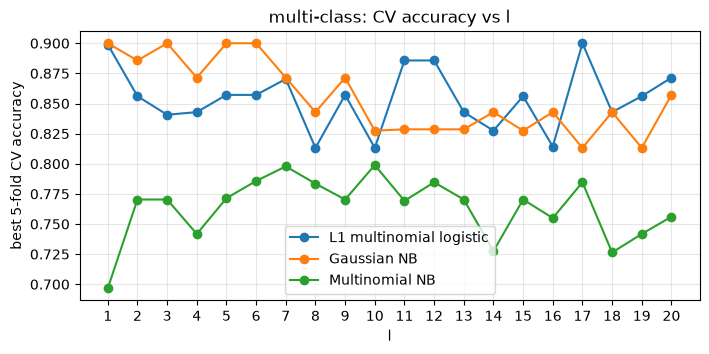

In [32]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(cv_mn.index, cv_mn.cv_acc, 'o-', label='L1 multinomial logistic')
for name in NB_MODELS:
    ax.plot(cv_nb[name].index, cv_nb[name].cv_acc, 'o-', label=name)
ax.set(xlabel='l', ylabel='best 5-fold CV accuracy', xticks=list(L_VALUES), title='multi-class: CV accuracy vs l')
ax.legend(); ax.grid(alpha=.3)
plt.show()

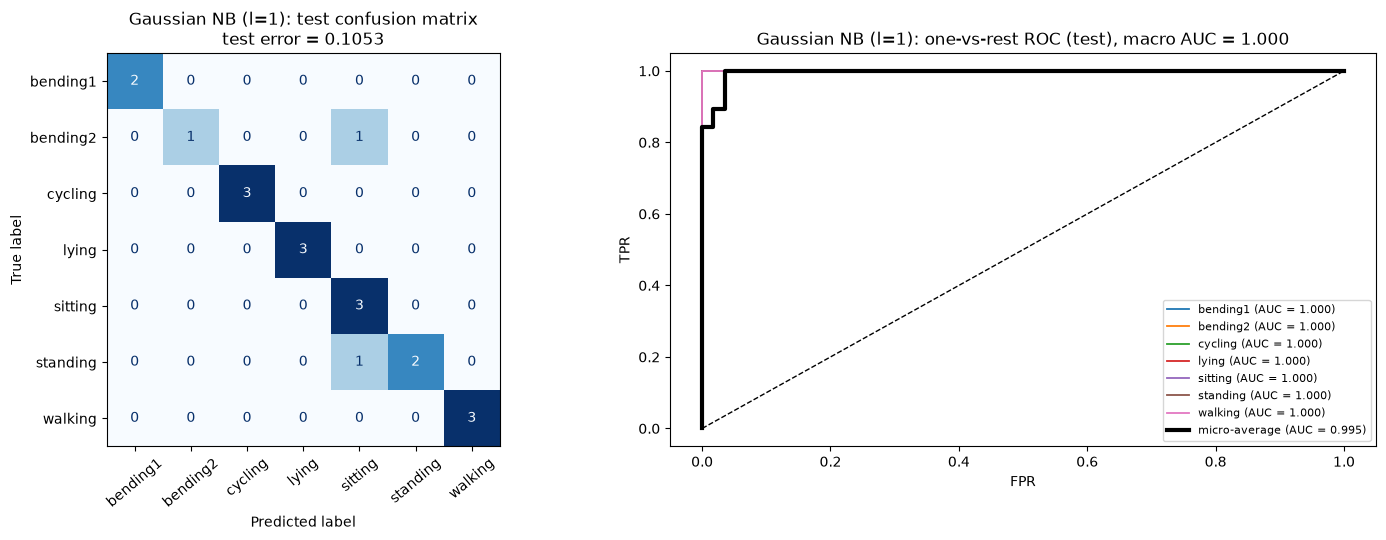

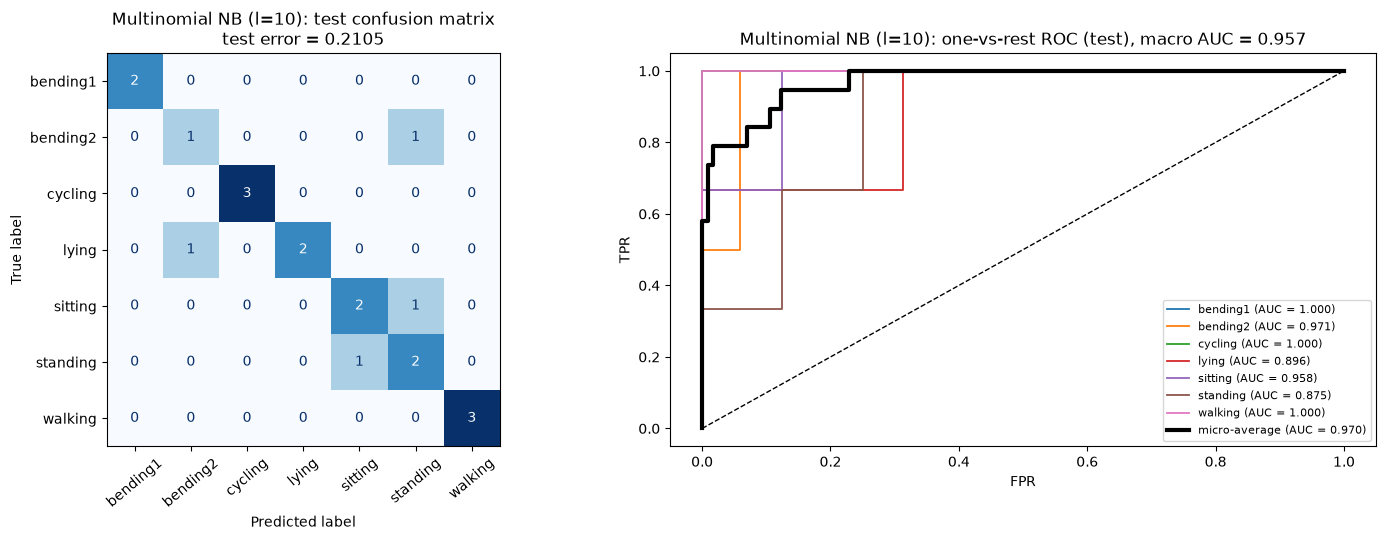

In [33]:
pd.concat(cv_nb, names=['model']).to_csv(os.path.join(OUT_DIR, 'multiclass_nb_cv.csv'))

res_nb = {}
for name, (pipe, grid) in NB_MODELS.items():
    l, param, _ = best_nb[name]
    Xtr, ytr, Xte, yte = split_xy(FEATS[l], target='multi')
    m = pipe.set_params(**{next(iter(grid)): param}).fit(Xtr, ytr)
    res_nb[name] = show_multi(m, Xtr, ytr, Xte, yte, f'{name} (l={l})')

**Gaussian vs. Multinomial Naïve Bayes.**
* **Gaussian NB** chooses `l = 1` (CV accuracy 0.900) and has **test error 0.105** (2 of 19: one `bending2` → sitting, one standing → sitting). Its probabilities rank the test set perfectly in every one-vs-rest problem (macro AUC 1.0); the two errors are cases where the wrong class had a slightly higher posterior.
* **Multinomial NB** chooses `l = 10` (CV accuracy 0.799) and has **test error 0.211** (4 of 19), again mostly among the static activities (sitting/standing/lying/bending2).
* **Gaussian is clearly better.** The features are continuous measurements (mean, std, max of signal strengths), and a class-specific normal with its own mean and variance per feature models them well. Multinomial NB is designed for counts (e.g. word counts). After min-max scaling it treats the feature values as counts, so its log-likelihood is linear in x, $\sum_j x_j \log\theta_{kj}$, and it ignores how spread out each feature is within each class. That throws away useful information.

#### 2(c)iii Which method is better for multi-class classification here?

In [34]:
summary = {'L1 multinomial logistic': {'l': L_C, 'CV accuracy': best_c.cv_acc, **res_c}}
for name, (l, _, acc) in best_nb.items():
    summary[name] = {'l': l, 'CV accuracy': acc, **res_nb[name]}
summary = pd.DataFrame(summary).T
summary.to_csv(os.path.join(OUT_DIR, 'multiclass_summary.csv'), index_label='model')
summary.round(4)

,l,CV accuracy,test error,train error,micro AUC,macro AUC,Hand-Till AUC
L1 multinomial logistic,17.0,0.9000,0.2632,0.0000,0.9774,0.9613,0.9616
Gaussian NB,1.0,0.9000,0.1053,0.0435,0.9954,1.0000,1.0000
Multinomial NB,10.0,0.7989,0.2105,0.0580,0.9700,0.9571,0.9590


**Gaussian Naïve Bayes is the best method for this problem.** It has the lowest test error (0.105 vs. 0.211 for Multinomial NB and 0.263 for L1 multinomial logistic regression), shares the best CV accuracy (0.900), has the best AUCs, and is the simplest model (18 features at `l = 1`, closed-form fit, no tuning to speak of).

Why the simple model wins: there are only 69 training instances for 7 classes (4–12 per class). In this regime variance is the main problem. Naïve Bayes has very few parameters (a mean and a variance per feature and class) and a strong assumption (independence), which means a lot of bias but little variance. The L1 multinomial model at `l = 17` estimates 7 × 306 coefficients, fits the training data perfectly (training error 0), and generalizes worse.

Caveats: the test set has only 19 instances, so the gap between the methods is 2–3 instances. GNB and L1 logistic regression have the *same* CV accuracy, and all methods have trouble with **sitting vs. standing**, the pair that the six RSS signals hardly distinguish.

---
## 3. ISLR 4.8.3

**Problem (paraphrased).** QDA with a single feature (p = 1): K classes, and within class k, $X \sim N(\mu_k, \sigma_k^2)$ with a class-specific variance. Prove that the Bayes classifier is not linear, and argue that it is quadratic.

**Proof.** The Bayes classifier assigns $x$ to the class with the largest posterior probability. By Bayes' theorem,
$$p_k(x) = P(Y = k \mid X = x) = \frac{\pi_k f_k(x)}{\sum_{l=1}^K \pi_l f_l(x)}, \qquad f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k}\exp\!\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).$$

The denominator is the same for every k, so maximizing $p_k(x)$ over k is the same as maximizing $\pi_k f_k(x)$, and since log is increasing, the same as maximizing
$$\log\big(\pi_k f_k(x)\big) = \log\pi_k - \tfrac12\log(2\pi) - \log\sigma_k - \frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

The term $-\tfrac12\log(2\pi)$ is the same for all classes and can be dropped. Expanding the square gives the discriminant function
$$\delta_k(x) = -\frac{x^2}{2\sigma_k^2} + \frac{\mu_k}{\sigma_k^2}\,x - \frac{\mu_k^2}{2\sigma_k^2} - \log\sigma_k + \log\pi_k,$$
and the Bayes classifier assigns $x$ to $\arg\max_k \delta_k(x)$.

$\delta_k(x)$ is of the form $a_k x^2 + b_k x + c_k$ with
$$a_k = -\frac{1}{2\sigma_k^2}, \quad b_k = \frac{\mu_k}{\sigma_k^2}, \quad c_k = -\frac{\mu_k^2}{2\sigma_k^2} - \log\sigma_k + \log\pi_k .$$

The decision boundary between classes k and l is where $\delta_k(x) = \delta_l(x)$:
$$\left(\frac{1}{2\sigma_l^2} - \frac{1}{2\sigma_k^2}\right)x^2 + \left(\frac{\mu_k}{\sigma_k^2} - \frac{\mu_l}{\sigma_l^2}\right)x + (c_k - c_l) = 0.$$

* If $\sigma_k \ne \sigma_l$ the coefficient of $x^2$ is non-zero, so the discriminant functions and the boundary are **quadratic** in x, not linear. (The boundary equation can have two roots, so a class can be assigned on both sides of another class, e.g. the class with the larger variance wins for very small *and* very large x — something no linear classifier can do.)
* The $x^2$ term only cancels when $\sigma_k = \sigma_l$ for all classes; that is exactly the LDA assumption, which gives the linear discriminant $\delta_k(x) = x\,\mu_k/\sigma^2 - \mu_k^2/(2\sigma^2) + \log\pi_k$.

So with class-specific variances the Bayes classifier is not linear; it is quadratic. $\blacksquare$

---
## 4. ISLR 4.8.7

**Problem (paraphrased).** Predict whether a company issues a dividend this year (Yes/No) from X = last year's percent profit. Companies that issued a dividend have mean $\bar X = 10$, those that didn't have mean $\bar X = 0$, the common variance is $\hat\sigma^2 = 36$, and 80% of companies issued dividends. Assuming X is normal, find the probability of a dividend given X = 4.

**Solution.** Bayes' theorem with normal class densities that share the variance $\sigma^2 = 36$ ($\sigma = 6$):
$$P(\text{Yes} \mid X = x) = \frac{\pi_{Y}\, f_{Y}(x)}{\pi_{Y}\, f_{Y}(x) + \pi_{N}\, f_{N}(x)},\qquad f_k(x) = \frac{1}{\sqrt{2\pi\sigma^2}}\exp\!\left(-\frac{(x-\mu_k)^2}{2\sigma^2}\right),$$
with $\pi_Y = 0.8,\ \mu_Y = 10,\ \pi_N = 0.2,\ \mu_N = 0$.

Since the variance is shared, the factor $1/\sqrt{2\pi\sigma^2}$ cancels:
$$P(\text{Yes} \mid X = 4) = \frac{0.8\, e^{-(4-10)^2/72}}{0.8\, e^{-(4-10)^2/72} + 0.2\, e^{-(4-0)^2/72}} = \frac{0.8\, e^{-1/2}}{0.8\, e^{-1/2} + 0.2\, e^{-2/9}}$$
$$= \frac{0.8 \times 0.60653}{0.8 \times 0.60653 + 0.2 \times 0.80074} = \frac{0.48522}{0.48522 + 0.16015} = \frac{0.48522}{0.64537} \approx \mathbf{0.752}.$$

So the probability that the company issues a dividend is about **75.2%**. (Even though X = 4 is closer to the "No" mean 0 than to the "Yes" mean 10, the large prior of 80% for "Yes" outweighs it.) A numeric check:

In [35]:
mu_yes, mu_no, sigma, pi_yes = 10, 0, 6, 0.8
x = 4
num = pi_yes * stats.norm.pdf(x, mu_yes, sigma)
den = num + (1 - pi_yes) * stats.norm.pdf(x, mu_no, sigma)
print(f'P(Yes | X=4) = {num / den:.4f}')

P(Yes | X=4) = 0.7519
